# 第13周：街道环境质量代理神经网络预测

复用冻结的空间划分和训练尺度目标，外部验证早停、参数选择，测试集只作结果评价。

# 第13周：多层感知机预测实验

沿用环境质量代理目标及基线实验冻结数据。视觉目标训练176、验证55、测试73条道路；完整目标训练26、验证13、测试7条。数据按约500米空间网格分组，同一网格不跨集合，但相邻网格没有空间缓冲。继续排除评分组成项及其变换作为输入。两套特征为道路属性、道路属性加建筑/天空/人物背景。背景与标签同源，可能共享识别误差，预测能力不等于独立环境效度。

## 模型与参数调整

使用scikit-learn MLPRegressor、Adam优化器。预先固定8个配置，比较16/32单层、32–16双层，ReLU/tanh激活，0.001/0.005学习率，0.0001/0.01 L2正则。配置表中只实现指定组合，并非所有参数的完整笛卡尔积。每个配置固定三个种子42/52/62，两任务×两特征集×八配置×三种子，共96次训练。

训练集拟合缺值填补、类别编码、数值缩放；MLP额外对目标做训练集均值/标准差缩放，评价前还原为0–100目标分尺度。目标原值直接读取基线的训练尺度目标，不再重新拟合分位数。输出预测不截断。

每次partial_fit执行一轮，仅使用训练样本更新权重；每轮记录训练/验证MAE及缩放尺度训练损失。外部验证MAE改善超过0.0001时保存模型，连续50轮无改善停止，最多600轮。关闭内部early_stopping以避免另行随机拆出验证数据；取外部验证最佳轮次权重。验证集参与早停和参数选择，验证误差会偏乐观。

配置由三个固定种子的验证MAE平均值选择；主结果预先固定种子42，另外两个种子用于稳定性展示，不按测试表现挑选随机种子。各任务再依据验证均值确定优先特征集。选定配置后才计算测试指标。测试集沿用此前已报告的基线基准，不是新采集的最终盲测集；没有根据本轮测试结果修改参数。

## 配置明细

| 配置 | 隐藏层 | 激活 | 学习率 | L2 |
| --- | --- | --- | --- | --- |
| C01 | (16,) | relu | 0.001 | 0.0 |
| C02 | (32,) | relu | 0.001 | 0.0 |
| C03 | (32, 16) | relu | 0.001 | 0.0 |
| C04 | (32,) | tanh | 0.001 | 0.0 |
| C05 | (32,) | relu | 0.005 | 0.0 |
| C06 | (32,) | relu | 0.001 | 0.01 |
| C07 | (32,) | tanh | 0.005 | 0.01 |
| C08 | (32, 16) | relu | 0.005 | 0.01 |

## 验证集选定结果

- visual_proxy：road_context、C08；测试 n=73，MAE=11.117，RMSE=13.713，R²=0.471。
- complete_proxy：road_only、C01；测试 n=7，MAE=13.652，RMSE=18.358，R²=0.118。

## 主种子神经网络与既有基线测试对比

| task | feature_set | model | n | MAE | RMSE | R2 |
| --- | --- | --- | --- | --- | --- | --- |
| visual_proxy | road_only | mean | 73 | 14.785 | 18.906 | -0.006 |
| visual_proxy | road_only | linear | 73 | 13.502 | 17.195 | 0.168 |
| visual_proxy | road_only | random_forest | 73 | 13.326 | 17.093 | 0.178 |
| visual_proxy | road_only | gradient_boosting | 73 | 13.564 | 17.219 | 0.166 |
| visual_proxy | road_context | mean | 73 | 14.785 | 18.906 | -0.006 |
| visual_proxy | road_context | linear | 73 | 10.563 | 13.933 | 0.454 |
| visual_proxy | road_context | random_forest | 73 | 12.291 | 15.308 | 0.341 |
| visual_proxy | road_context | gradient_boosting | 73 | 13.072 | 16.219 | 0.26 |
| complete_proxy | road_only | mean | 7 | 20.974 | 23.542 | -0.451 |
| complete_proxy | road_only | linear | 7 | 15.19 | 17.315 | 0.215 |
| complete_proxy | road_only | random_forest | 7 | 15.987 | 18.413 | 0.113 |
| complete_proxy | road_only | gradient_boosting | 7 | 16.067 | 18.304 | 0.123 |
| complete_proxy | road_context | mean | 7 | 20.974 | 23.542 | -0.451 |
| complete_proxy | road_context | linear | 7 | 12.981 | 14.526 | 0.448 |
| complete_proxy | road_context | random_forest | 7 | 12.829 | 14.781 | 0.428 |
| complete_proxy | road_context | gradient_boosting | 7 | 10.371 | 11.264 | 0.668 |
| visual_proxy | road_only | MLP | 73 | 13.835 | 17.389 | 0.149 |
| visual_proxy | road_context | MLP | 73 | 11.117 | 13.713 | 0.471 |
| complete_proxy | road_only | MLP | 7 | 13.652 | 18.358 | 0.118 |
| complete_proxy | road_context | MLP | 7 | 8.742 | 12.172 | 0.612 |

## 随机初始化稳定性

| task | feature_set | test_MAE_mean | test_MAE_std | test_RMSE_mean | test_R2_mean |
| --- | --- | --- | --- | --- | --- |
| complete_proxy | road_context | 14.466 | 4.958 | 17.822 | 0.127 |
| complete_proxy | road_only | 13.389 | 3.185 | 16.183 | 0.298 |
| visual_proxy | road_context | 11.313 | 0.233 | 13.993 | 0.449 |
| visual_proxy | road_only | 13.591 | 0.421 | 17.374 | 0.15 |

上述标准差只反映三个随机初始化种子的差异，不是对道路样本或空间划分的不确定性置信区间。完整目标只有7条测试道路，不依据其表现确定模型稳定优劣。

visual_proxy：神经网络验证选定结果相对既有验证选定基线的测试MAE变化 +5.2%。两者可能选用不同特征集，公平的同特征对比另见对比表。负值表示误差减少，正值表示误差增加，不预设神经网络必然优于传统模型。

complete_proxy：神经网络验证选定结果相对既有验证选定基线的测试MAE变化 +5.2%。两者可能选用不同特征集，公平的同特征对比另见对比表。负值表示误差减少，正值表示误差增加，不预设神经网络必然优于传统模型。

## 文件与复现

参数实验记录保存全部96次训练、验证指标、轮次和耗时；逐轮训练过程保存学习曲线；参数方案验证集对比用于审查选择依据；误差表与逐道路预测保存选定配置的三种子结果；joblib模型包括预处理、目标缩放器和神经网络权重。使用项目中的Jupyter Notebook可重跑。

实现参考[scikit-learn MLPRegressor文档](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPRegressor.html)。实际运行版本记录在实验摘要中。


,task,feature_set,config_id,validation_MAE_mean,validation_MAE_std,best_epoch_mean
0,complete_proxy,road_context,C01,18.201487,4.845411,180.000000
1,complete_proxy,road_context,C02,24.000558,15.093193,53.333333
2,complete_proxy,road_context,C03,26.197025,8.563601,58.333333
3,complete_proxy,road_context,C04,20.927435,5.761783,70.000000
4,complete_proxy,road_context,C05,22.174819,13.476162,51.000000
5,complete_proxy,road_context,C06,23.994070,15.082340,53.666667
6,complete_proxy,road_context,C07,19.380549,3.926756,13.666667
7,complete_proxy,road_context,C08,25.090621,6.775898,19.333333
8,complete_proxy,road_only,C01,13.416729,1.734024,8.000000
9,complete_proxy,road_only,C02,22.607206,3.499066,131.333333


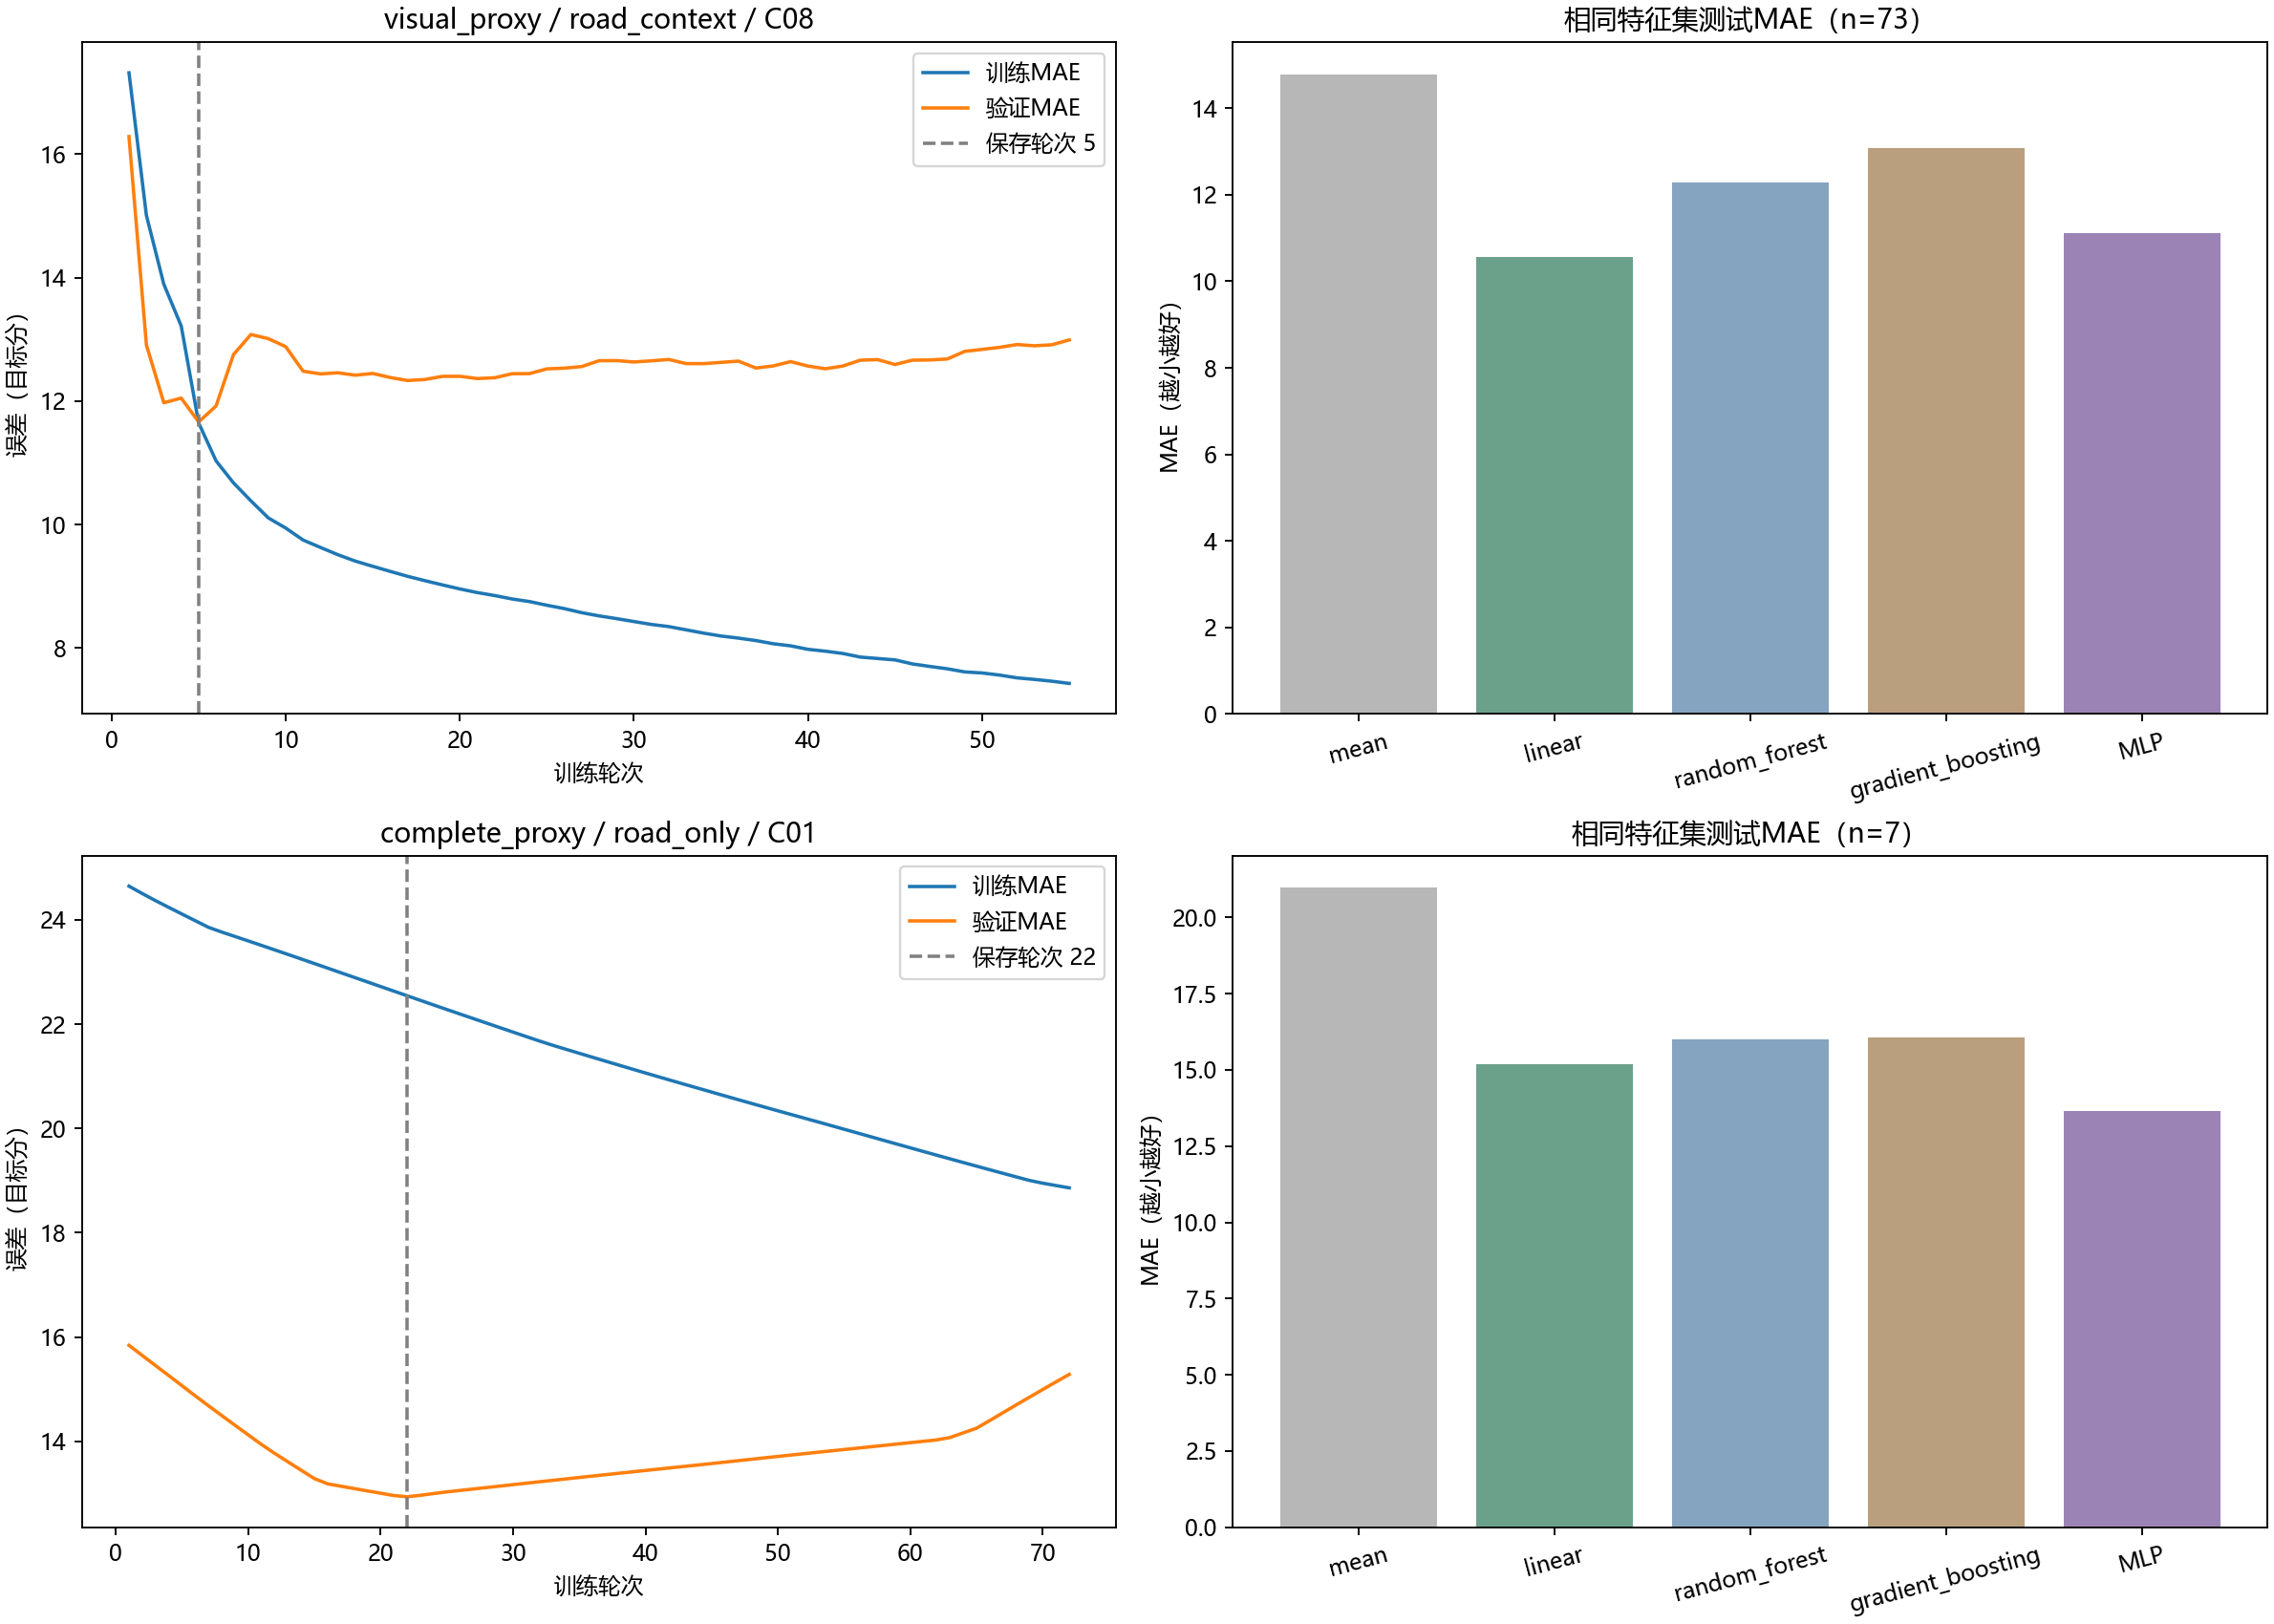

In [1]:
from pathlib import Path
import subprocess,sys,json
import pandas as pd
from IPython.display import display,Markdown,Image
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'scripts/train_environment_mlp.py').exists())
OUT=ROOT/'outputs/environment_mlp_week13'
RUN_TRAINING=True
if RUN_TRAINING:
    subprocess.run([sys.executable,'-u',str(ROOT/'scripts/train_environment_mlp.py')],cwd=ROOT,check=True)
display(Markdown((OUT/'第13周神经网络实验结果.md').read_text(encoding='utf-8')))
display(pd.read_csv(OUT/'参数方案验证集对比.csv',encoding='utf-8-sig'))
display(Image(filename=str(OUT/'神经网络学习曲线与模型对比.png')))
